In [38]:
from langgraph.graph import StateGraph , START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langgraph.checkpoint.memory import MemorySaver

In [32]:
load_dotenv()

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0.7
)

In [33]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict):

  messages:Annotated[list[BaseMessage],add_messages]
  

In [34]:
def chat_node(state:ChatState):

  # take user query from state
  messages = state['messages']

  # send it to llm
  response = llm.invoke(messages)

  # response store state
  return {'messages':[response]}

In [41]:
checkpointer = MemorySaver()

graph = StateGraph(ChatState)

# add nodes
graph.add_node('chat_node',chat_node)

# add Edges
graph.add_edge(START,'chat_node')
graph.add_edge('chat_node',END)

chatbot = graph.compile(checkpointer=checkpointer)

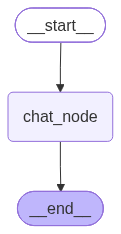

In [42]:
chatbot

In [47]:
thread_id = '1'

while True:

  user_message = input("Type here: ")

  print('User: ',user_message)
  if user_message.strip().lower() in ['exit','quit','bye']:
    break

  config = {'configurable':{'thread_id':thread_id}}

  response = chatbot.invoke({'messages':[HumanMessage(content=user_message)]},config=config)

  print("AI: ",response['messages'][-1].content)

User:  bye


In [48]:
chatbot.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='hi my name is krishna', additional_kwargs={}, response_metadata={}, id='9de026c5-dfee-4bb8-93f5-acd4a15db418'), AIMessage(content='Hello Krishna! 👋 Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "hi my name is krishna". Likely they want a response. Should greet and ask how can help. Keep friendly.'}, response_metadata={'token_usage': {'completion_tokens': 56, 'prompt_tokens': 77, 'total_tokens': 133, 'completion_time': 0.115775889, 'completion_tokens_details': {'reasoning_tokens': 30}, 'prompt_time': 0.003233485, 'prompt_tokens_details': None, 'queue_time': 0.211501883, 'total_time': 0.119009374}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_27194a498a', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a18050-2762-7052-8013-07922c9b5f11-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={